# Faz 2 — Veri temizleme ve ön işleme

Bu notebook vize kriteri **5**'i (veri kalitesi sorunlarının belirlenmesi, temizleme/dönüştürme yöntemleri,
öncesi–sonrası karşılaştırma) karşılar.

**Girdi:** Faz 1 çıktıları (`veri/islenmis/cagrilar_eslesmis.parquet`, `fiyat_pencereleri.parquet`) ve MAEC metinleri.
Önce `01_veri_edinme_eslestirme.ipynb` çalıştırılmış olmalı.

**Test ayrımı:** Temizlik ve ön işleme bütün çağrıların girdilerine uygulanır (etikete bakmayan, sabit kurallar). Hedefe ya da
sınıfa dayanan her ölçüm yalnız geliştirme döneminden (≤ 2016) yapılır; test döneminin (2017+) sınıfları yalnız sayılır.
**Çıktı:** `veri/islenmis/temiz_cagrilar.parquet` (temiz metin + etiket), `veri/islenmis/seri_girdisi.npz`
(60 × 3 fiyat girdisi), `sekiller/f2_*.png`, `cikti/f2_*.csv`. Süre ~1 dk.

In [1]:
import re
import sys
import textwrap
from pathlib import Path

KOK = Path.cwd().resolve().parent
sys.path.insert(0, str(KOK))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from src import etiket, temizle, veri

SEKIL, CIKTI, ISLENMIS = KOK / "sekiller", KOK / "cikti", KOK / "veri" / "islenmis"
SINIF_RENK = ["#6da7ec", "#2a78d6", "#104281"]
MAVI, TURUNCU, GRI, KOYU = "#2a78d6", "#eb6834", "#9a9893", "#3a3a38"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.facecolor": "white", "axes.titlesize": 11})
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)


def kaydet(fig, ad):
    fig.savefig(SEKIL / f"{ad}.png", bbox_inches="tight")


def tr(x, nd=0):
    """Sayıyı Türkçe yazar: binlik nokta, ondalık virgül."""
    return f"{x:,.{nd}f}".replace(",", "§").replace(".", ",").replace("§", ".").replace("-", "−")


VIRGUL = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ",").replace("-", "−"))

tablo = pd.read_parquet(ISLENMIS / "cagrilar_eslesmis.parquet").set_index("klasor")
pencere = pd.read_parquet(ISLENMIS / "fiyat_pencereleri.parquet")
cumleler = veri.maec_oku().set_index("klasor").loc[tablo.index, "cumleler"]
print("Faz 1'den gelen eşleşmiş çağrı:", len(tablo), "| fiyat penceresi satırı:", len(pencere))

Faz 1'den gelen eşleşmiş çağrı: 3026 | fiyat penceresi satırı: 217872


## 1. Veri kalitesi sorunlarının envanteri (Kriter 5)

Her sorun ölçülür, sonra bir karar verilir. Faz 1'de ele alınanlar da bütünlük için tabloda yer alır.

### Tekrar kayıt kontrolü

İki tür tekrar aranır: (a) birebir aynı metin, (b) aynı şirketin iki çağrısının büyük ölçüde aynı cümlelerden oluşması
(ör. aynı çağrının iki farklı tarihle kaydedilmesi). İkincisi için her şirketin çağrı çiftlerinde cümle kümelerinin
Jaccard benzerliği (ortak cümle / toplam farklı cümle) hesaplanır. Çok kısa metinlerde Jaccard anlamsız biçimde yüksek
çıkar (ör. iki "Thank you." metni = 1,0); bu metinler (a)'da ve Bölüm 2'deki içeriksiz metin kuralında ele alındığı için
(b)'ye yalnız iki çağrısı da 5'ten fazla farklı cümle içeren çiftler alınır; dışarıda kalan çift sayısı çıktıda.

In [2]:
import itertools

birlesik = pd.Series([" ".join(s) for s in cumleler], index=cumleler.index)
birebir = birlesik[birlesik.duplicated(keep=False)]
print(f"Birebir aynı metne sahip çağrı: {len(birebir)} | farklı metin sayısı: {birebir.nunique()} | metin: {list(birebir.unique())}")
ciftler, disarida = [], 0
for _, grup in tablo.groupby("ticker"):
    for k1, k2 in itertools.combinations(grup.index, 2):
        A, B = set(cumleler[k1]), set(cumleler[k2])
        disarida += not (len(A) > 5 and len(B) > 5)
        if len(A) > 5 and len(B) > 5:
            ciftler.append((len(A & B) / len(A | B), k1, k2, abs((tablo.tarih[k2] - tablo.tarih[k1]).days)))
ciftler = pd.DataFrame(ciftler, columns=["jaccard", "cagri_1", "cagri_2", "gun_farki"]).sort_values("jaccard", ascending=False)
jaccard_max = ciftler.jaccard.max()
print(f"Aynı şirketin çağrı çifti (ikisi de > 5 farklı cümle): {len(ciftler):,} | en yüksek Jaccard: {jaccard_max:.3f} | 0,5'in üstünde: {int((ciftler.jaccard > 0.5).sum())}"
      f" | çok kısa metin yüzünden dışarıda kalan çift: {disarida}")
print("45 günden kısa arayla yapılmış aynı şirket çağrıları (aynı çağrının iki kaydı olabilir mi?):")
display(ciftler[ciftler.gun_farki < 45].round(3))
ciftler.head(5).round(3)

Birebir aynı metne sahip çağrı: 17 | farklı metin sayısı: 1 | metin: ['Thank you.']


Aynı şirketin çağrı çifti (ikisi de > 5 farklı cümle): 4,255 | en yüksek Jaccard: 0.101 | 0,5'in üstünde: 0 | çok kısa metin yüzünden dışarıda kalan çift: 142
45 günden kısa arayla yapılmış aynı şirket çağrıları (aynı çağrının iki kaydı olabilir mi?):


,jaccard,cagri_1,cagri_2,gun_farki


,jaccard,cagri_1,cagri_2,gun_farki
4202,0.101,20170504_WWE,20170727_WWE,84
1304,0.098,20170801_ECL,20171031_ECL,91
3094,0.097,20180122_PETS,20180507_PETS,105
1963,0.095,20150721_IBKR,20151020_IBKR,91
739,0.094,20150504_CHUY,20150804_CHUY,92


In [3]:
metin_ham = [" ".join(s) for s in cumleler]
kelime_ham = tablo.n_kelime
g_girdi = pencere[pencere.gun.between(-60, -1)]
gelistirme = tablo.index[tablo.tarih <= "2016-12-31"]           # hedefe dayanan ölçümler yalnız bu çağrılarla
g_hedef = pencere[pencere.gun.between(0, 6) & pencere.klasor.isin(gelistirme)]
esik_f1 = etiket.esikler(tablo.loc[gelistirme, "v"])
yakin = np.min(np.abs(tablo.loc[gelistirme, "v"].to_numpy()[:, None] - esik_f1[None, :]), axis=1) < 0.10
h01 = g_hedef[g_hedef.gun.isin([0, 1])].pivot(index="klasor", columns="gun", values="getiri").abs()
sifir_hedef = g_hedef.groupby("klasor").getiri.apply(lambda s: int((s == 0).sum()))
sifir_girdi = g_girdi.groupby("klasor").getiri.apply(lambda s: (s == 0).mean())
ayni_metin = pd.Series(metin_ham).duplicated(keep=False)
cumle_uzunluk = np.array([len(x.split()) for s in cumleler for x in s])
kalip = temizle.kalip_say(metin_ham)

envanter = pd.DataFrame([
    ("Eksik veri", "fiyat", "ticker'ı FNSPID'de olmayan çağrı", "411", "Faz 1'de çıkarıldı"),
    ("Bozuk dosya", "fiyat", "kesik dosya (SON, SAFM tek satır; SPN, SJI geç başlıyor)", "6 çağrı", "Faz 1'de çıkarıldı"),
    ("Eksik veri", "fiyat", "girdi/hedef penceresinde eksik gün ya da getiri", "0", "işlem gerekmez"),
    ("Eksik veri", "metin", f"içeriksiz metin (≤ {temizle.MIN_KELIME} kelime)", f"{int((kelime_ham <= temizle.MIN_KELIME).sum())} çağrı", "çıkarılır (Bölüm 2)"),
    ("Tekrar kayıt", "metin", "birebir aynı metin", f"{int(ayni_metin.sum())} çağrı (hepsi \"Thank you.\")", "içeriksiz metin kuralıyla çıkar"),
    ("Tekrar kayıt", "metin", "aynı şirketin çağrı çiftlerinde en yüksek cümle benzerliği (Jaccard)", f"{tr(jaccard_max, 3)} (> 0,5 olan çift: {int((ciftler.jaccard > 0.5).sum())})", "kopya yok; işlem gerekmez"),
    ("Kalite düşüklüğü", "metin", "dökümcü notu ([indiscernible], (ph) …)", f"{kalip['dökümcü notu ([indiscernible], (ph) …)']['toplam']}", "silinir (Bölüm 3)"),
    ("Kalite düşüklüğü", "metin", "köşeli parantezli ekleme ([million] …)", f"{kalip['köşeli parantezli ekleme ([million] …)']['toplam']}", "parantez kaldırılır, içerik kalır"),
    ("Kalite düşüklüğü", "metin", "<UNK> (gizlenmiş kişi adı)", f"{kalip['<UNK> (gizlenmiş kişi adı)']['toplam']}", "[NAME] olarak tekilleştirilir"),
    ("Kalite düşüklüğü", "metin", "tipografik karakter / HTML varlığı / URL",
     f"{kalip['tipografik karakter (’ – … •)']['toplam']} / {kalip['HTML varlığı (&amp; …)']['toplam']} / {kalip['URL']['toplam']}", "düz karşılığa çevrilir / [URL]"),
    ("Aykırı değer", "metin", "çok uzun \"cümle\" (cümle bölme hatası)", f"en uzun {cumle_uzunluk.max()} kelime (%99: {int(np.percentile(cumle_uzunluk, 99))})", "korunur; model cümle sınırına dayanmıyor"),
    ("Aykırı değer", "fiyat", "|günlük log getiri| > 0,4: girdi penceresi (tümü) / hedef penceresi (geliştirme)",
     f"{int((g_girdi.getiri.abs() > 0.4).sum())} / {int((g_hedef.getiri.abs() > 0.4).sum())} gün", "incelenir (Bölüm 4); korunur"),
    ("Kalite düşüklüğü", "fiyat", "hedef penceresinde ≥ 3 gün sıfır getiri (geliştirme)", f"{int((sifir_hedef >= 3).sum())} çağrı", "işlem hacmi var; gerçek (Bölüm 4)"),
    ("Kalite düşüklüğü", "fiyat", "girdi penceresinin > %10'u sıfır getiri", f"{int((sifir_girdi > 0.1).sum())} çağrı", "işlem hacmi var; gerçek (Bölüm 4)"),
    ("Kalite düşüklüğü", "fiyat", "yüksek < düşük, kapanış aralık dışında, hacim 0/NaN",
     f"{int((g_girdi.high < g_girdi.low).sum() + (g_girdi.close > g_girdi.high * 1.0001).sum() + (g_girdi.close < g_girdi.low * 0.9999).sum() + (g_girdi.volume <= 0).sum() + g_girdi.volume.isna().sum())}", "işlem gerekmez"),
    ("Etiket sorunu", "etiket", "bir eşiğe 0,10 log biriminden yakın (geliştirme; temizlik öncesi, Faz 1 eşikleri)", f"{int(yakin.sum())} çağrı (%{tr(100 * yakin.mean(), 1)})", "korunur; belirsizlik raporlanır"),
    ("Etiket sorunu", "etiket", "çağrı saati yok (BMO/AMC karışık; geliştirme, temizlik öncesi)", f"|r0| > |r+1|: %{tr(100 * (h01[0] > h01[1]).mean(), 1)}", "hedef penceresi gün 0..+6 (Faz 1 Bölüm 4.2)"),
], columns=["tür", "modalite", "sorun", "ölçüm", "karar"])
envanter.to_csv(CIKTI / "f2_kalite_envanteri.csv", index=False)
envanter

,tür,modalite,sorun,ölçüm,karar
0,Eksik veri,fiyat,ticker'ı FNSPID'de olmayan çağrı,411,Faz 1'de çıkarıldı
1,Bozuk dosya,fiyat,"kesik dosya (SON, SAFM tek satır; SPN, SJI geç başlıyor)",6 çağrı,Faz 1'de çıkarıldı
2,Eksik veri,fiyat,girdi/hedef penceresinde eksik gün ya da getiri,0,işlem gerekmez
3,Eksik veri,metin,içeriksiz metin (≤ 20 kelime),26 çağrı,çıkarılır (Bölüm 2)
4,Tekrar kayıt,metin,birebir aynı metin,"17 çağrı (hepsi ""Thank you."")",içeriksiz metin kuralıyla çıkar
5,Tekrar kayıt,metin,aynı şirketin çağrı çiftlerinde en yüksek cümle benzerliği (Jaccard),"0,101 (> 0,5 olan çift: 0)",kopya yok; işlem gerekmez
6,Kalite düşüklüğü,metin,"dökümcü notu ([indiscernible], (ph) …)",1132,silinir (Bölüm 3)
7,Kalite düşüklüğü,metin,köşeli parantezli ekleme ([million] …),1867,"parantez kaldırılır, içerik kalır"
8,Kalite düşüklüğü,metin,<UNK> (gizlenmiş kişi adı),29465,[NAME] olarak tekilleştirilir
9,Kalite düşüklüğü,metin,tipografik karakter / HTML varlığı / URL,4503 / 1 / 161,düz karşılığa çevrilir / [URL]


**Ne gözlendi:** Fiyat tarafındaki sorunların çoğu Faz 1'de ele alındı (eksik ticker, kesik dosya); eşleşen çağrılarda eksik gün yok; girdi penceresinde tutarsız yüksek/düşük fiyat ya da sıfır hacim yok. Metin tarafında sorunlar biçimsel: 29.465 gizlenmiş ad, 1.132 dökümcü notu, 1.867 köşeli parantezli ekleme, 4.503 tipografik karakter, 161 URL. Birebir aynı 17 metin gerçek tekrar değil; hepsi yalnız "Thank you." içeren, muhtemelen hizalaması başarısız kayıtlar. Aynı şirketin 4.255 çağrı çiftinde (iki çağrısı da 5'ten fazla farklı cümle içeren çiftler) en yüksek cümle benzerliği 0,101; 0,5'i geçen ya da 45 günden kısa arayla yapılmış çift yok, yani aynı çağrının iki kez kaydedildiği bir durum yok.

**Neden önemli:** Değerlendirme yönergesi (Kriter 5) sorunların araştırılıp sayısallaştırılmasını ister; her satır bir ölçüm ve bir kararla eşleşiyor. Aykırı görünen bazı değerler (|getiri| > 0,4, sıfır getirili günler) Bölüm 4'te incelendiğinde gerçek piyasa davranışı çıkıyor; bunları "temizlemek" veriyi bozardı.

**Sonraki aşamaya etkisi:** Bölüm 2–5'te kararlar uygulanıyor ve üç öncesi–sonrası karşılaştırmayla (Bölüm 2, 3, 5) gösteriliyor.

## 2. Öncesi–sonrası 1: içeriksiz metinlerin çıkarılması

**Yöntem:** Kelime sayısı ≤ 20 olan metinler çıkarılır. **Gerekçe:** Bu aralıktaki 26 metnin tamamı aşağıda
listeleniyor; çağrının içeriğine dair bilgi taşımıyorlar. 21–100 kelimelik metinlerin bir kısmı da yalnız kapanış
cümlesi, ama bir kısmı rakamlı, gerçek içerik taşıyor (sayısı ve örnekleri aşağıda). Bu yüzden eşik tutucu seçildi ve
daha yükseğe çekilmedi; kalan kısa metinlerin modelde eksik modaliteye yakın davranması beklenir (ör. Faz 3 Bölüm 6'daki CMI).

In [4]:
kisa = tablo[tablo.n_kelime <= temizle.MIN_KELIME].sort_values("n_kelime")
print(f"≤ {temizle.MIN_KELIME} kelimelik metin: {len(kisa)} çağrı (tamamı):")
for k in kisa.index:
    print(f"  {k} ({kisa.n_kelime[k]} kelime): {' '.join(cumleler[k])}")
orta = tablo[(tablo.n_kelime > temizle.MIN_KELIME) & (tablo.n_kelime <= 100)].sort_values("n_kelime")
rakamli = [k for k in orta.index if any(ch.isdigit() for ch in " ".join(cumleler[k]))]
print(f"\nKarşılaştırma için 21–100 kelimelik metin: {len(orta)} çağrı; rakam içeren (sayısal içerik): {len(rakamli)}. "
      "Eşit aralıklı 6 örnek:")
for k in orta.index[np.linspace(0, len(orta) - 1, 6).astype(int)]:
    print(f"  {k} ({orta.n_kelime[k]} kelime): {textwrap.shorten(' '.join(cumleler[k]), 110)}")

≤ 20 kelimelik metin: 26 çağrı (tamamı):
  20150506_NSIT (2 kelime): Thank you.
  20151105_HE (2 kelime): Thank you.
  20150819_LZB (2 kelime): Thank you.
  20150508_WELL (2 kelime): Thank you.
  20160414_BAC (2 kelime): Thank you.
  20160426_PCAR (2 kelime): Thank you.
  20160128_GNTX (2 kelime): Thank you.
  20160217_GRMN (2 kelime): Thank you.
  20160426_WAB (2 kelime): Thank you.
  20160728_AEP (2 kelime): Thank you.
  20170215_ADI (2 kelime): Thank you.
  20170209_UFS (2 kelime): Thank you.
  20161020_FAF (2 kelime): Thank you.
  20160815_SYY (2 kelime): Thank you.
  20160805_MTX (2 kelime): Thank you.
  20160729_PFS (2 kelime): Thank you.
  20170222_LZB (2 kelime): Thank you.
  20150504_TXRH (3 kelime): Thanks a lot.
  20180220_SMP (3 kelime): Thank you. Bye.
  20170209_FWRD (3 kelime): Thank you. Okay.
  20170216_CHTR (9 kelime): All right. Thank you everybody. Thanks, everyone. Thank you.
  20150422_SNBR (10 kelime): Yes. In the 53rd week, right, in the fourth quarter.
  201511

,önce,sonra,çıkan,önce %,sonra %
sinif,,,,,
düşük,629,618,11,33.35,33.12
orta,628,622,6,33.30,33.33
yüksek,629,626,3,33.35,33.55
toplam,1886,1866,20,100.00,100.00


Çıkan çağrı (tüm dönem): 26 (%0.86) | geliştirme döneminde: 20 | sınıf paylarındaki en büyük değişim (geliştirme): 0.23 yüzde puan


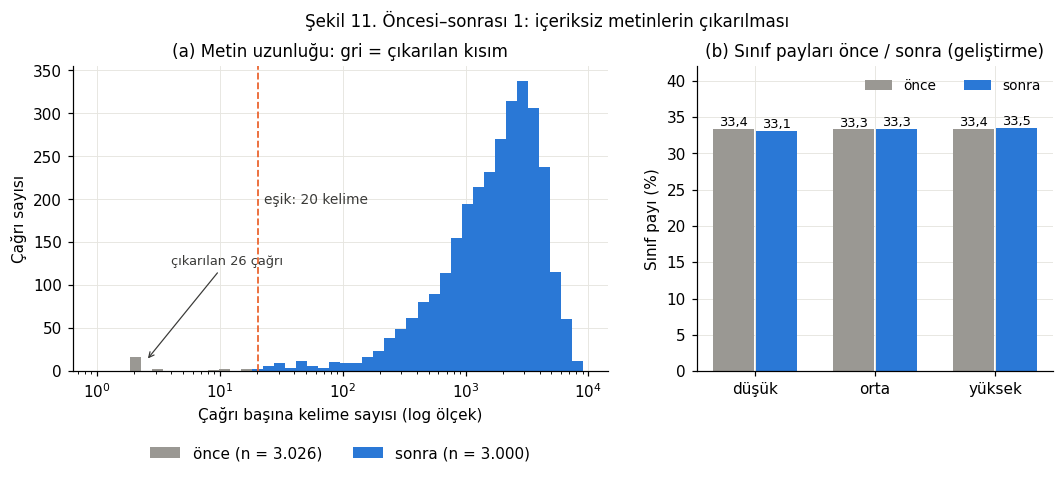

In [5]:
tut = tablo.n_kelime > temizle.MIN_KELIME
tg = tablo.loc[gelistirme]
once = tg.sinif.value_counts().sort_index()                    # sınıf etkisi yalnız geliştirme döneminde ölçülür
sonra = tg[tut.loc[gelistirme]].sinif.value_counts().sort_index()
kiyas = pd.DataFrame({"önce": once, "sonra": sonra, "çıkan": once - sonra}).rename(index=dict(enumerate(etiket.SINIF_ADLARI)))
kiyas["önce %"] = (100 * kiyas["önce"] / kiyas["önce"].sum()).round(2)
kiyas["sonra %"] = (100 * kiyas["sonra"] / kiyas["sonra"].sum()).round(2)
kiyas.loc["toplam"] = [once.sum(), sonra.sum(), once.sum() - sonra.sum(), 100, 100]
display(kiyas)
print(f"Çıkan çağrı (tüm dönem): {int((~tut).sum())} (%{100 * (~tut).mean():.2f}) | geliştirme döneminde: {int((~tut.loc[gelistirme]).sum())} | sınıf paylarındaki en büyük değişim (geliştirme): "
      f"{(kiyas['sonra %'] - kiyas['önce %']).iloc[:3].abs().max():.2f} yüzde puan")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
kutular = np.logspace(0, np.log10(tablo.n_kelime.max() + 1), 45)
a1.hist(tablo.n_kelime.clip(lower=1), bins=kutular, color=GRI, label=f"önce (n = {tr(len(tablo))})")
a1.hist(tablo[tut].n_kelime, bins=kutular, color=MAVI, label=f"sonra (n = {tr(tut.sum())})")
a1.axvline(temizle.MIN_KELIME + 0.5, color=TURUNCU, lw=1.2, ls="--")
a1.text(temizle.MIN_KELIME * 1.15, a1.get_ylim()[1] * 0.55, f"eşik: {temizle.MIN_KELIME} kelime", fontsize=9, color=KOYU)
a1.set_xscale("log")
a1.set_xlabel("Çağrı başına kelime sayısı (log ölçek)")
a1.set_ylabel("Çağrı sayısı")
a1.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
a1.set_title("(a) Metin uzunluğu: gri = çıkarılan kısım")
a1.annotate(f"çıkarılan {int((~tut).sum())} çağrı", xy=(2.5, 12), xytext=(4, a1.get_ylim()[1] * 0.35), fontsize=8.5, color=KOYU,
            arrowprops={"arrowstyle": "->", "color": KOYU, "lw": 0.8})
x = np.arange(3)
for j, (kol, renk) in enumerate([("önce %", GRI), ("sonra %", MAVI)]):
    a2.bar(x + (j - 0.5) * 0.36, kiyas[kol].iloc[:3], width=0.34, color=renk, label=kol.replace(" %", ""))
    for xi, p in zip(x, kiyas[kol].iloc[:3]):
        a2.text(xi + (j - 0.5) * 0.36, p + 0.4, tr(p, 1), ha="center", fontsize=8.5)
a2.set_xticks(x, etiket.SINIF_ADLARI)
a2.set_ylabel("Sınıf payı (%)")
a2.set_ylim(0, 42)
a2.legend(frameon=False, fontsize=9, loc="upper right", ncol=2)
a2.set_title("(b) Sınıf payları önce / sonra (geliştirme)")
fig.suptitle("Şekil 11. Öncesi–sonrası 1: içeriksiz metinlerin çıkarılması", y=1.02, fontsize=11)
kaydet(fig, "f2_01_iceriksiz_metin")
plt.show()

**Ne gözlendi:** 26 çağrı (%0,86) çıkarıldı; bunların 20'si geliştirme döneminde (11 düşük, 6 orta, 3 yüksek). Geliştirme döneminde sınıf paylarındaki en büyük değişim 0,23 yüzde puan. Çıkan 26 metnin 24'ü yalnız teşekkür ya da kapanış cümlesi, 2'si bağlamsız parça (SNBR: "Yes. In the 53rd week, right, in the fourth quarter."; DE: "And then was proposed by our actuarial company, so --"). 21–100 kelimelik 57 metnin 20'si rakam içeriyor; bu bantta kapanıştan ibaret metinler (ör. CMI, PNC) de, gerçek içerik taşıyanlar (ör. ELY) da var.

**Neden önemli:** Bu çağrılarda metin modalitesi fiilen yok; modele boş metin vermek, metnin katkısını ölçerken gürültü yaratırdı. Kayıp küçük ve sınıf dengesini bozmuyor.

**Sonraki aşamaya etkisi:** Nihai veri 3.000 çağrı. Bilgi kaybı: 26 çağrının fiyat serisi de kullanılmıyor; finalde eksik metinli çağrılarla tek-modalite (yalnız fiyat) dayanıklılık denemesi istenirse bu kayıtlar `cagrilar_eslesmis.parquet` içinde duruyor.

## 3. Öncesi–sonrası 2: metin gürültüsünün temizlenmesi

**Yöntem (`src/temizle.py`, cümle cümle):**
1. HTML varlıkları (`&amp;`) ve tipografik karakterler (’ – … •) düz karşılığına çevrilir.
2. Dökümcü notları (`[indiscernible]`, `[ph]`, `(inaudible)`, `[laughter]` …) silinir: konuşmacının söylediği bir şey değil, yazıya dökenin notu.
3. Köşeli parantezli eklemelerde (`[million]`) parantez kaldırılır, içerik kalır: dökümcünün anlamı netleştirmek için eklediği kelimedir.
4. URL'ler `[URL]`, MAEC'in gizlediği kişi adları (`<UNK>`) `[NAME]` olarak tek biçime getirilir.
5. Fazla boşluklar tekilleştirilir; temizlik sonrası boş kalan cümle atılır.

**Bilerek yapılmayanlar:** Küçük harfe çevirme, noktalama ve durak kelime silme, kök bulma. Bu adımlar kullanılacak
modele göre değişir (ör. TF-IDF'te sözlük aşamasında yapılır, önceden eğitilmiş transformer modellerinde hiç
yapılmaz); veri aşamasında yapılırsa geri alınamaz bilgi kaybı olur. Konuşmadaki duraksamaları gösteren `--` de korunur.

In [6]:
temiz = {k: temizle.metin_temizle(cumleler[k]) for k in tablo.index[tut]}
metin_once = [" ".join(cumleler[k]) for k in temiz]
metin_sonra = [" ".join(s) for s in temiz.values()]
k_once, k_sonra = temizle.kalip_say(metin_once), temizle.kalip_say(metin_sonra)
gurultu = pd.DataFrame({"önce (metin)": {a: v["metin"] for a, v in k_once.items()}, "önce (toplam)": {a: v["toplam"] for a, v in k_once.items()},
                        "sonra (toplam)": {a: v["toplam"] for a, v in k_sonra.items()}})
display(gurultu)


def sozluk(metinler):
    return {w for t in metinler for w in re.findall(r"[A-Za-z][A-Za-z'-]*", t.lower())}


kelime_once = sum(len(t.split()) for t in metin_once)
kelime_sonra = sum(len(t.split()) for t in metin_sonra)
s_once, s_sonra = sozluk(metin_once), sozluk(metin_sonra)
cumle_once = sum(len(cumleler[k]) for k in temiz)
cumle_sonra = sum(len(s) for s in temiz.values())
olcu = pd.DataFrame({"önce": [kelime_once, len(s_once), cumle_once, sum(len(t) for t in metin_once)],
                     "sonra": [kelime_sonra, len(s_sonra), cumle_sonra, sum(len(t) for t in metin_sonra)]},
                    index=["toplam kelime", "farklı kelime türü (küçük harf)", "cümle", "karakter"])
olcu["fark"] = olcu["sonra"] - olcu["önce"]
olcu["değişim %"] = (100 * (olcu["sonra"] - olcu["önce"]) / olcu["önce"]).round(3)
display(olcu)
print("Temizlikle sözlükten çıkan kelime türlerinden örnekler:", sorted(s_once - s_sonra)[:25])
print(f"Temiz metinlerin medyan uzunluğu: {np.median([len(t.split()) for t in metin_sonra]):,.1f} kelime ({len(metin_sonra):,} çağrı)")
for w, desen in [("hotus", r"hotus"), ("annie", r"\bAnnie’")]:          # Annie’s: tipografik kesme işaretli biçim
    m_ = next(m for m in (re.search(desen, t) for t in metin_once) if m)
    print(f"'{w}' temizlik öncesi bağlam: …{m_.string[max(0, m_.start() - 40):m_.start() + 30]}…")

,önce (metin),önce (toplam),sonra (toplam)
"dökümcü notu ([indiscernible], (ph) …)",634,1132,1
köşeli parantezli ekleme ([million] …),902,1867,6
URL,149,161,0
<UNK> (gizlenmiş kişi adı),2796,29465,0
tipografik karakter (’ – … •),194,4503,0
HTML varlığı (&amp; …),1,1,0


,önce,sonra,fark,değişim %
toplam kelime,6695821,6694353,-1468,-0.022
farklı kelime türü (küçük harf),45620,45603,-17,-0.037
cümle,346643,346585,-58,-0.017
karakter,38477126,38485234,8108,0.021


Temizlikle sözlükten çıkan kelime türlerinden örnekler: ['ain', 'alamo-group', 'alexanderbaldwin', 'american-equity', 'annie', 'aren', 'arnott', 'aswater', 'bankatfirst', 'bedbathandbeyond', 'bet-the', 'calwatergroup', 'centralpacificbank', 'couldn', 'criminally', 'dentsplysirona', 'dsystems', 'earningsslidesmarch', 'elpolloloco', 'encorewire', 'ensigngroup', 'fspreit', 'greif', 'hadn', 'hotus']


Temiz metinlerin medyan uzunluğu: 1,953.5 kelime (3,000 çağrı)
'hotus' temizlik öncesi bağlam: … posted on the Company's website at www.hotus.com. The earnings releas…


'annie' temizlik öncesi bağlam: …ment over last quarter led by growth in Annie’s, Nature Valley, and La…


In [7]:
ornekler = []
for desen in [r"\[indiscernible\]", r"\(ph\)", r"\[(?:million|billion)\]", r"’", r"www\.|https?://"]:
    for k in temiz:
        hit = [s for s in cumleler[k] if re.search(desen, s) and len(s) < 160]
        if hit:
            ornekler.append({"klasor": k, "önce": hit[0], "sonra": temizle.cumle_temizle(hit[0])})
            break
display(pd.DataFrame(ornekler))
kalan = [(k, m.group(0)) for k, s in zip(temiz, metin_sonra) for desen in (temizle.NOTLAR, temizle.KOSELI) for m in desen.finditer(s)]
print(f"Temizlikten sonra kalan not/parantez geçişi: {len(kalan)}")
for k, m in kalan:
    print(f"  {k}: {m!r}")

,klasor,önce,sonra
0,20170126_ADS,What that means is free cash flow at the [indiscernible] will be up a little bit year-over-year,What that means is free cash flow at the will be up a little bit year-over-year
1,20150226_GPS,"So as a Company that has $16 [billion], roughly, in revenue, there's a lot of space out there.","So as a Company that has $16 billion, roughly, in revenue, there's a lot of space out there."
2,20170117_CMA,We don’t really look at it that way,We don't really look at it that way
3,20150428_HELE,"<UNK>, I'd like to inform all interested parties that a copy of today's earnings release has been posted on the Comp...","[NAME], I'd like to inform all interested parties that a copy of today's earnings release has been posted on the Com..."


Temizlikten sonra kalan not/parantez geçişi: 7
  20150730_CRL: '[market. ]'
  20160209_CNC: '[That has to change. ]'
  20160505_INTL: '(sic. see slide 7)'
  20160526_SPTN: '[shivole. ]'
  20161026_NBR: '[No. ]'
  20170223_CLDT: '[thick. Prime is thick]'
  20180508_ANIP: '[statement, yes. ]'


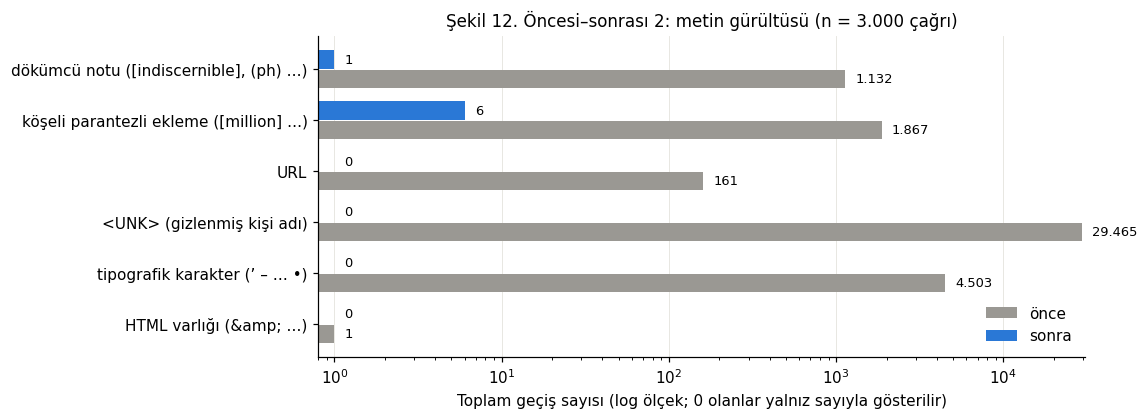

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(gurultu))
ax.barh(y + 0.19, gurultu["önce (toplam)"].where(gurultu["önce (toplam)"] > 0), height=0.36, color=GRI, label="önce")   # 0 olanlara çubuk çizilmez
ax.barh(y - 0.19, gurultu["sonra (toplam)"].where(gurultu["sonra (toplam)"] > 0), height=0.36, color=MAVI, label="sonra")
ax.set_xlim(left=0.8)
for yi, (o, s) in enumerate(zip(gurultu["önce (toplam)"], gurultu["sonra (toplam)"])):
    ax.text(max(o, 1) * 1.15, yi + 0.19, tr(o), va="center", fontsize=8.5)
    ax.text(max(s, 1) * 1.15, yi - 0.19, tr(s), va="center", fontsize=8.5)
ax.set_xscale("log")
ax.set_yticks(y, gurultu.index)
ax.invert_yaxis()
ax.set_xlabel("Toplam geçiş sayısı (log ölçek; 0 olanlar yalnız sayıyla gösterilir)")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_title(f"Şekil 12. Öncesi–sonrası 2: metin gürültüsü (n = {tr(len(temiz))} çağrı)")
kaydet(fig, "f2_02_metin_gurultusu")
plt.show()

**Ne gözlendi:** Temizlik sonrası dökümcü notları 1.132'den 1'e, köşeli parantezli eklemeler 1.867'den 6'ya, URL, gizlenmiş ad ve tipografik karakterler sıfıra indi. Toplam kelime %0,022, farklı kelime türü %0,037, cümle sayısı 58 (%0,017) azaldı. Kalan 1 not ve 6 parantez, MAEC'in cümle bölme hatası yüzünden iki cümleye bölünmüş eklemeler (ör. "[market. ]"); temizlik cümle cümle yapıldığı için yakalanmadı.

**Neden önemli:** Temizlik yalnız konuşma olmayan işaretleri kaldırdı; konuşmanın içeriği neredeyse hiç değişmedi (kelime kaybı binde birin altında). Sözlükten "kaybolan" kelimelerin bir kısmı URL'lerin parçası, bir kısmı da tipografik kesme işaretinin düzelmesiyle başka biçime geçen kelimeler (ör. hotus ve annie; temizlik öncesi bağlamları çıktıda).

**Sonraki aşamaya etkisi:** Metin, model aşamasında seçilecek gösterime (TF-IDF ya da önceden eğitilmiş dil modeli) hazır. Temiz 3.000 metnin medyan uzunluğu 1.953,5 kelime (çıktıda); girdi uzunluğu sınırlı olan BERT türü modellerde metnin parçalara bölünüp birleştirilmesi gerekecek.

## 4. Sıfır getirili günler ve uç getiriler: veri hatası mı, gerçek mi?

Faz 1'de bazı çağrılarda kapanış fiyatının günlerce değişmediği görüldü. Fiyat sağlayıcısında donmuş bir kayıt olsaydı
o günlerde işlem hacmi de olmamalıydı. Bu yüzden sıfır getirili günlerdeki hacim ve hissenin fiyat düzeyi incelenir.

In [9]:
supheli = sorted(set(sifir_hedef[sifir_hedef >= 3].index) | set(sifir_girdi[sifir_girdi > 0.1].index))
g = pencere[pencere.gun.between(-60, -1) | (pencere.gun.between(0, 6) & pencere.klasor.isin(gelistirme))]
sifir_gun = g[(g.getiri == 0) & g.klasor.isin(supheli)]
fiyat_duzeyi = g.groupby("klasor").close.median()
print(f"Şüpheli çağrı tanımı: hedef penceresinde ≥ 3 sıfır getirili gün (yalnız geliştirme): {int((sifir_hedef >= 3).sum())} ∪ "
      f"girdi penceresinin > %10'u sıfır getiri (tüm çağrılar): {int((sifir_girdi > 0.1).sum())} → {len(supheli)} çağrı")
print("Sayılan günler: girdi penceresi (tüm çağrılar) + hedef penceresi (yalnız geliştirme); test hedef pencereleri dahil değil")
print(f"Şüpheli çağrı: {len(supheli)} | bu çağrılardaki sıfır getirili gün: {len(sifir_gun)} | "
      f"bunlardan hacmi 0 olan: {int((sifir_gun.volume == 0).sum())} | en düşük hacim: {int(sifir_gun.volume.min()):,}")
print(f"Kapanış fiyatı medyanı: şüpheli çağrılarda {fiyat_duzeyi[supheli].median():.2f} $, tüm çağrılarda {fiyat_duzeyi.median():.2f} $")
sifir_pay = g[g.gun.between(-60, -1)].groupby("klasor").getiri.apply(lambda s: (s == 0).mean())
print(f"Fiyat düzeyi ile sıfır getiri payı (girdi penceresi) arasındaki Spearman korelasyonu: {fiyat_duzeyi.corr(sifir_pay, method='spearman'):.3f}")
en_dusuk = tablo.loc[gelistirme, "v"].sort_values().index[:3]           # en düşük hedef oynaklıklı 3 geliştirme çağrısı
for k in en_dusuk:
    h_ = g_hedef[g_hedef.klasor == k]
    print(f"En düşük v: {k} | v = {tablo.v[k]:.2f} | hedefte sıfır getirili gün: {int((h_.getiri == 0).sum())} | "
          f"hedefte en düşük hacim: {int(h_.volume.min()):,} | ortalama |getiri|: %{100 * h_.getiri.abs().mean():.2f}")

Şüpheli çağrı tanımı: hedef penceresinde ≥ 3 sıfır getirili gün (yalnız geliştirme): 2 ∪ girdi penceresinin > %10'u sıfır getiri (tüm çağrılar): 25 → 27 çağrı
Sayılan günler: girdi penceresi (tüm çağrılar) + hedef penceresi (yalnız geliştirme); test hedef pencereleri dahil değil
Şüpheli çağrı: 27 | bu çağrılardaki sıfır getirili gün: 242 | bunlardan hacmi 0 olan: 0 | en düşük hacim: 6,600
Kapanış fiyatı medyanı: şüpheli çağrılarda 10.55 $, tüm çağrılarda 40.23 $


Fiyat düzeyi ile sıfır getiri payı (girdi penceresi) arasındaki Spearman korelasyonu: -0.392
En düşük v: 20160721_RJF | v = -6.11 | hedefte sıfır getirili gün: 0 | hedefte en düşük hacim: 430,900 | ortalama |getiri|: %0.39
En düşük v: 20160815_SYY | v = -5.63 | hedefte sıfır getirili gün: 0 | hedefte en düşük hacim: 2,272,100 | ortalama |getiri|: %0.30
En düşük v: 20150527_CHS | v = -5.59 | hedefte sıfır getirili gün: 2 | hedefte en düşük hacim: 1,552,700 | ortalama |getiri|: %0.26


**Uç getiriler:** |log getiri| > 0,4 olan günler (girdi penceresi tüm çağrılarda, hedef penceresi yalnız geliştirme
döneminde) iki yoldan sınanır. (1) Düzeltilmemiş kapanışla karşılaştırma: fark büyük olsaydı uç değer bir temettü düzeltmesi
hatası olurdu. FNSPID'deki `close` sütunu da bölünmeye göre düzeltilmiş göründüğü için (Faz 1'deki ACIW 1995 kapanışı
2,979167 = 143/48; dönemin kesirli fiyat adımlarına uymuyor) bu karşılaştırma bölünme hatasını yakalayamaz. (2) Bu yüzden o
günün işlem hacmi ve gün içi aralığı, çağrının girdi penceresindeki medyanla karşılaştırılır: mekanik bir bölünme sıçraması
hacim patlaması üretmez; haber kaynaklı gerçek bir hareket üretir.

In [10]:
pz = pencere.sort_values(["klasor", "gun"]).copy()
pz["getiri_duzeltilmemis"] = np.log(pz.close).groupby(pz.klasor).diff()
uc_gun = pz[(pz.getiri.abs() > 0.4) & (pz.gun.between(-60, -1) | (pz.gun.between(0, 6) & pz.klasor.isin(gelistirme)))]
gi = pz[pz.gun.between(-60, -1)]
medyan_hacim = gi.groupby("klasor").volume.median()
medyan_aralik = np.log(gi.high / gi.low).groupby(gi.klasor).median()
uc_gun = uc_gun.assign(fark=(uc_gun.getiri - uc_gun.getiri_duzeltilmemis).abs(),
                       hacim_kat=uc_gun.volume / uc_gun.klasor.map(medyan_hacim),
                       aralik_kat=np.log(uc_gun.high / uc_gun.low) / uc_gun.klasor.map(medyan_aralik))
print(f"|getiri| > 0,4 olan çağrı-gün: {len(uc_gun)} (farklı hisse-gün: {len(set(zip(uc_gun.klasor.str.split('_').str[1], uc_gun.date)))}) | "
      f"iki getiri arasındaki en büyük mutlak fark: {uc_gun.fark.max():.4f} | hacmi 0 olan: {int((uc_gun.volume == 0).sum())}")
print(f"Hacim / girdi medyanı: {uc_gun.hacim_kat.min():.1f}–{uc_gun.hacim_kat.max():.1f} kat | gün içi aralık / girdi medyanı: "
      f"{uc_gun.aralik_kat.min():.1f}–{uc_gun.aralik_kat.max():.1f} kat | çağrının gün 0 ya da +1'i olan: {int(uc_gun.gun.isin([0, 1]).sum())}")
uc_gun[["klasor", "gun", "date", "getiri", "getiri_duzeltilmemis", "volume", "hacim_kat", "aralik_kat"]].round(
    {"getiri": 4, "getiri_duzeltilmemis": 4, "hacim_kat": 1, "aralik_kat": 1}).reset_index(drop=True)

|getiri| > 0,4 olan çağrı-gün: 10 (farklı hisse-gün: 9) | iki getiri arasındaki en büyük mutlak fark: 0.0000 | hacmi 0 olan: 0
Hacim / girdi medyanı: 3.3–43.6 kat | gün içi aralık / girdi medyanı: 2.2–24.1 kat | çağrının gün 0 ya da +1'i olan: 5


,klasor,gun,date,getiri,getiri_duzeltilmemis,volume,hacim_kat,aralik_kat
0,20151029_CENX,-58,2015-08-07,-0.4618,-0.4618,14682000.0,5.1,4.9
1,20151106_LXU,0,2015-11-06,-0.5802,-0.5802,10818200.0,43.6,21.7
2,20160224_CHK,-11,2016-02-08,-0.4055,-0.4055,121984600.0,4.6,5.6
3,20160226_HSC,0,2016-02-26,-0.4668,-0.4668,7062400.0,9.7,9.6
4,20160503_AROC,0,2016-05-03,-0.4575,-0.4575,2504600.0,3.3,2.2
5,20160504_HSC,-47,2016-02-26,-0.4668,-0.4668,7062400.0,8.8,7.4
6,20160505_ENDP,1,2016-05-06,-0.4974,-0.4974,57847400.0,9.4,2.7
7,20160804_LNTH,1,2016-08-05,0.4334,0.4334,1836900.0,13.6,5.7
8,20161103_GEO,-54,2016-08-18,-0.5038,-0.5038,37203100.0,20.5,24.1
9,20180510_FTK,-13,2018-04-23,-0.4206,-0.4206,8796100.0,9.1,5.7


**Ne gözlendi:** Şüpheli 27 çağrı (hedefte ≥ 3 sıfır getirili gün: 2, girdinin > %10'u sıfır getiri: 25) içindeki 242 sıfır
getirili günün hepsinde işlem hacmi var (en düşük 6.600) ve bu çağrılar çoğunlukla düşük fiyatlı hisselere ait (medyan
kapanış 10,55 $; tüm çağrılarda 40,23 $); fiyat düzeyi ile sıfır getiri payı negatif ilişkili (ρ = −0,392). En düşük
hedef oynaklıklı üç geliştirme çağrısında (RJF −6,11; SYY −5,63; CHS −5,59) hedef penceresinin her gününde işlem hacmi
var; RJF ve SYY'de sıfır getirili gün yok (SYY'nin metni yalnız "Thank you." olduğu için Bölüm 2'de zaten çıkarıldı).
|getiri| > 0,4 olan 10 çağrı-günde (9 farklı hisse-günü; HSC'nin 2016-02-26'sı iki çağrının penceresinde) düzeltilmiş ve
düzeltilmemiş kapanıştan hesaplanan getiriler aynı; o günlerin işlem hacmi girdi penceresi medyanının 3,3–43,6 katı, gün
içi aralığı 2,2–24,1 katı; 5'i doğrudan bir çağrının gün 0 ya da +1'i.

**Neden önemli:** Hisse fiyatı düştükçe en küçük fiyat adımı fiyata göre görece büyür ve kapanışın aynı kalması
olağanlaşır; bu günlerde bir veri hatası işareti yok. Uç günlerde temettü düzeltmesi hatası yok ve hacim patlaması
mekanik bir bölünme sıçramasıyla değil, haber kaynaklı gerçek hareketle tutarlı. İkisini de "temizlemek" hissenin
gerçek davranışını silerdi.

**Karar ve sonraki aşamaya etkisi:** İkisi de veride bırakılır. Etiket donuk fiyatlı çağrılarda düşük çıkabilir, ama bu,
hissenin gerçek davranışıdır. Kırpma uygulanmadı; finalde gerekirse kırpma eşiği, Faz 4'teki standartlaştırma gibi yalnız
kat eğitiminden öğrenilecek.

## 5. Öncesi–sonrası 3: fiyat serisinin model girdisine dönüştürülmesi

**Sorun:** Ham seride hisseler arasında ölçek farkı çok büyük (çağrı başına ortalama fiyat yaklaşık 2 dolardan 1.869 dolara,
ortalama hacim yaklaşık 27 binden 70 milyon adede; aşağıdaki çıktı). Ayrıca düzeltilmiş kapanışın *düzeyi*, çağrıdan sonra gelen temettü ve bölünmelere göre geriye dönük
değişir; düzeyi modele vermek ileriye dönük bilgi sızıntısı olur.

**Yöntem (`src/temizle.py: seri_girdisi`), yalnız gün −60..−1:**
| Kanal | Tanım | Neden |
|---|---|---|
| getiri | ln(P_t / P_t−1), P = düzeltilmiş kapanış | Ölçekten bağımsız; oynaklığın doğrudan hammaddesi |
| göreli log hacim | ln(hacim_t) − pencerenin ln(hacim) ortalaması | Hisseler arası hacim farkını ve bölünme düzeltmesini siler; yalnız "olağandan fazla/az işlem" kalır |
| günlük aralık | ln(yüksek_t / düşük_t) | Gün içi oynaklık; aynı günün oranı olduğu için düzeltmeden etkilenmez |

Hepsi yalnız girdi penceresindeki günlerden hesaplanır; hedef penceresinden ya da başka çağrılardan bilgi kullanılmaz.
Kanalların ölçeklenmesi (standartlaştırma) yalnız kat (fold) eğitiminden öğrenilir; Faz 4 Bölüm 5'te kat 0 üzerinde gösterildi, finalde her katta aynı kuralla.

### 5.0 Zaman serisi hizalaması (Faz 1'de yapıldı, burada temiz veri için doğrulanır)

Her çağrının fiyat serisi takvim tarihine göre değil, olay gününe (t0) göre hizalanır: fiyat günleri −61..−1 girdiyi (getiriler −60..−1), gün 0..+6
hedefi oluşturur. Hisselerin işlem gördüğü günler piyasa takviminden saparsa (eksik gün) seri kayar; bu yüzden pencereler SPY'nin
işlem günü takvimiyle karşılaştırılır. Eksik gün olsaydı doldurma ya da yeniden örnekleme gerekecekti.

In [11]:
spy = veri.fiyat_oku(veri.fiyat_dosyalari()["SPY"])["date"].to_numpy()
p_ = pencere[pencere.klasor.isin(temiz.keys())]
uc = p_[p_.gun.isin([-61, -1, 0, 6])].pivot(index="klasor", columns="gun", values="date")


def piyasa_gunu(bas, son):
    return np.searchsorted(spy, son.to_numpy(), side="right") - np.searchsorted(spy, bas.to_numpy(), side="left")


eksik_girdi, eksik_hedef = piyasa_gunu(uc[-61], uc[-1]) - 61, piyasa_gunu(uc[0], uc[6]) - 7
gunler = p_.groupby("klasor").gun.agg(["min", "max"])
print(f"Hizalanmış çağrı: {len(uc):,} | gün −61..+6 tam olan: {int(((gunler['min'] == -61) & (gunler['max'] >= 6)).sum()):,}")
print("SPY takvimine göre eksik gün → girdi:", pd.Series(eksik_girdi).value_counts().to_dict(), "| hedef:", pd.Series(eksik_hedef).value_counts().to_dict())
print("Çağrı tarihi bir işlem günü olan (t0 = çağrı tarihi):", int((tablo.loc[list(temiz), "t0"] == tablo.loc[list(temiz), "tarih"]).sum()), "/", len(temiz))

Hizalanmış çağrı: 3,000 | gün −61..+6 tam olan: 3,000
SPY takvimine göre eksik gün → girdi: {0: 3000} | hedef: {0: 3000}
Çağrı tarihi bir işlem günü olan (t0 = çağrı tarihi): 3000 / 3000


**Sonuç:** Tüm pencereler olay gününe hizalı ve piyasa takvimiyle birebir örtüşüyor; doldurma ya da yeniden örnekleme
gerekmedi, dolayısıyla bu adımda bilgi kaybı yok.

In [12]:
X, sira = temizle.seri_girdisi(pencere[pencere.klasor.isin(temiz.keys())])
print("Girdi dizisi:", X.shape, "(çağrı × gün × kanal) | eksik değer:", int(np.isnan(X).sum()))
girdi = pencere[pencere.gun.between(-61, -1) & pencere.klasor.isin(temiz.keys())]
ort_fiyat = girdi.groupby("klasor")["adj close"].mean()
ort_hacim = girdi.groupby("klasor").volume.mean()


def yayilim(s):
    return f"{tr(s.min(), 2)} – {tr(s.max(), 2)} (en büyük / en küçük = {tr(s.max() / s.min())} kat)"


print("ÖNCE  ortalama düzeltilmiş fiyat:", yayilim(ort_fiyat))
print("ÖNCE  ortalama hacim         :", yayilim(ort_hacim))
oz = pd.DataFrame({k: pd.Series(X[:, :, i].ravel()).describe(percentiles=[.01, .5, .99]) for i, k in enumerate(temizle.KANALLAR)}).T
oz.round(4)

Girdi dizisi: (3000, 60, 3) (çağrı × gün × kanal) | eksik değer: 0
ÖNCE  ortalama düzeltilmiş fiyat: 1,98 – 1.869,43 (en büyük / en küçük = 942 kat)
ÖNCE  ortalama hacim         : 26.631,15 – 69.655.350,82 (en büyük / en küçük = 2.616 kat)


,count,mean,std,min,1%,50%,99%,max
getiri,180000.0,0.0005,0.0199,-0.5038,-0.0544,0.0008,0.0513,0.3407
goreli_log_hacim,180000.0,-0.0000,0.4238,-2.4056,-0.9015,-0.0290,1.2419,3.5281
gunluk_aralik,180000.0,0.0252,0.0173,0.0025,0.0066,0.0207,0.0894,0.6950


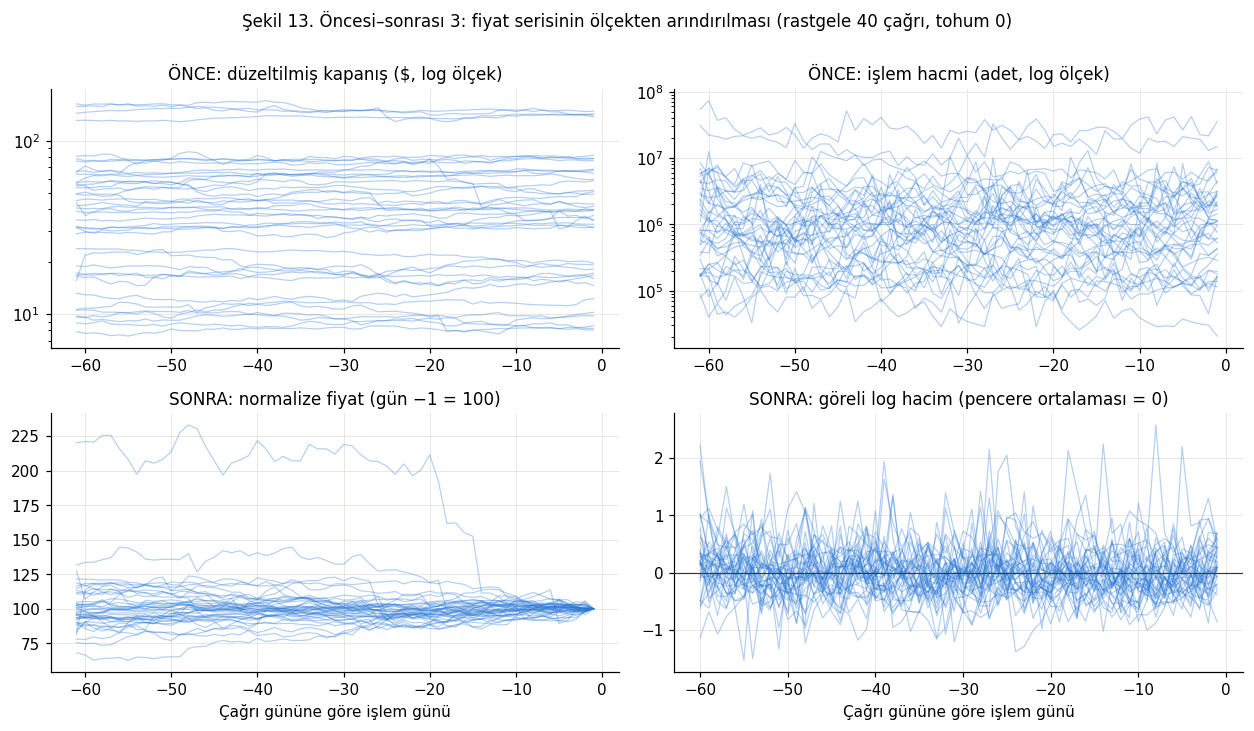

In [13]:
rng = np.random.default_rng(0)
secim = rng.choice(len(sira), 40, replace=False)
fig, eksen = plt.subplots(2, 2, figsize=(11.5, 6.6))
for j in secim:
    p = girdi[girdi.klasor == sira[j]]
    eksen[0, 0].plot(p.gun, p["adj close"], lw=0.8, alpha=0.35, color=MAVI)
    eksen[0, 1].plot(p.gun, p.volume, lw=0.8, alpha=0.35, color=MAVI)
    eksen[1, 0].plot(p.gun, 100 * p["adj close"] / p["adj close"].iloc[-1], lw=0.8, alpha=0.35, color=MAVI)
    eksen[1, 1].plot(range(-60, 0), X[j, :, 1], lw=0.8, alpha=0.35, color=MAVI)
eksen[0, 0].set_yscale("log"); eksen[0, 1].set_yscale("log")
eksen[0, 0].set_title("ÖNCE: düzeltilmiş kapanış ($, log ölçek)")
eksen[0, 1].set_title("ÖNCE: işlem hacmi (adet, log ölçek)")
eksen[1, 0].set_title("SONRA: normalize fiyat (gün −1 = 100)")
eksen[1, 1].set_title("SONRA: göreli log hacim (pencere ortalaması = 0)")
eksen[1, 1].axhline(0, color=KOYU, lw=0.8)
for ax in eksen[1]:
    ax.set_xlabel("Çağrı gününe göre işlem günü")
    ax.yaxis.set_major_formatter(VIRGUL)
fig.suptitle(f"Şekil 13. Öncesi–sonrası 3: fiyat serisinin ölçekten arındırılması (rastgele 40 çağrı, tohum 0)", y=1.0, fontsize=11)
fig.tight_layout()
kaydet(fig, "f2_03_seri_olcek")
plt.show()

**Ne gözlendi:** Ham seride çağrılar arası ortalama fiyat 1,98 $ ile 1.869,43 $ (942 kat), ortalama hacim 26.631 ile 69,7 milyon adet (2.616 kat) arasında değişiyor. Dönüşümden sonra üç kanal da hisseden bağımsız ölçekte: günlük getirinin ortalaması 0,0005 ve std'si 0,0199; göreli log hacmin ortalaması tanım gereği 0, std'si 0,42; günlük aralığın medyanı 0,021. Normalize fiyat yollarının hepsi gün −1'de 100'de buluşuyor; bu panel yalnız görselleştirme içindir, modele normalize fiyat değil ondan türeyen getiri kanalı girer.

**Neden önemli:** Ölçek farkı giderilmezse model hisseleri fiyat ya da hacim büyüklüğüyle ayırt eder, oynaklık örüntüsünü öğrenmez. Fiyat düzeyini atmak ayrıca ileriye dönük sızıntıyı engeller. Bilgi kaybı: şirket büyüklüğü ve fiyat düzeyi bilgisi atıldı; gerekirse sızıntısız bir büyüklük göstergesi ayrıca eklenebilir.

**Sonraki aşamaya etkisi:** Uç getiriler (en düşük −0,50, en yüksek +0,34) gerçek hareket olduğu için kırpılmadı; ölçekleme yalnız kat eğitiminden öğrenilir (Faz 4 Bölüm 5'te kat 0 üzerinde gösterildi), kırpma gerekirse finalde aynı kuralla öğrenilecek.

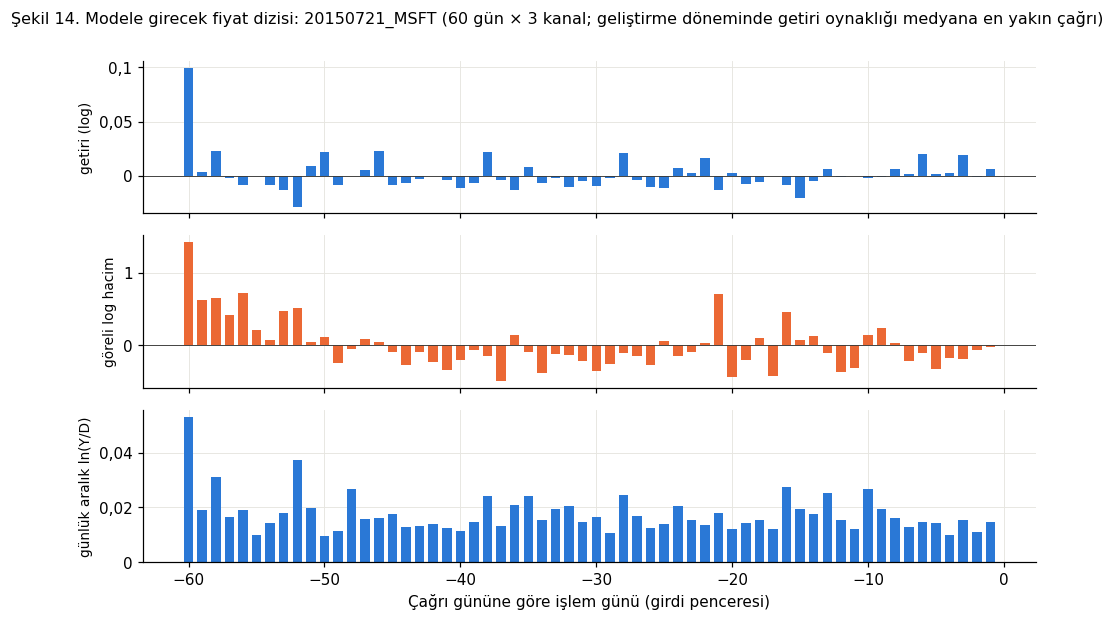

Seçim kuralı: 20150721_MSFT girdi getirisi std'si 0.01663 | geliştirme dönemi medyanı 0.01663
Örnek: 20150721_MSFT | Spearman(|getiri|, göreli log hacim) = 0.354 | Spearman(|getiri|, günlük aralık) = 0.373
en büyük |getiri| günleri (ilk 3): [-60, -52, -58]
en yüksek göreli hacim günleri (ilk 3): [-60, -56, -21]
en geniş aralık günleri (ilk 3): [-60, -52, -58]


In [14]:
s_ = X[:, :, 0].std(axis=1)
aday_ = np.where(np.isin(sira, gelistirme))[0]          # örnek geliştirme döneminden seçilir
j = aday_[np.argmin(np.abs(s_[aday_] - np.median(s_[aday_])))]
ornek = sira[j]
fig, eksen = plt.subplots(3, 1, figsize=(9, 5.6), sharex=True)
adlar = ["getiri (log)", "göreli log hacim", "günlük aralık ln(Y/D)"]
for i, ax in enumerate(eksen):
    ax.bar(range(-60, 0), X[j, :, i], color=MAVI if i != 1 else TURUNCU, width=0.7)
    ax.axhline(0, color=KOYU, lw=0.6)
    ax.set_ylabel(adlar[i], fontsize=9)
    ax.yaxis.set_major_formatter(VIRGUL)
eksen[-1].set_xlabel("Çağrı gününe göre işlem günü (girdi penceresi)")
fig.suptitle(f"Şekil 14. Modele girecek fiyat dizisi: {ornek} (60 gün × 3 kanal; geliştirme döneminde getiri oynaklığı medyana en yakın çağrı)", y=1.0, fontsize=10.5)
fig.tight_layout()
kaydet(fig, "f2_04_seri_kanallari")
plt.show()
print(f"Seçim kuralı: {ornek} girdi getirisi std'si {s_[j]:.5f} | geliştirme dönemi medyanı {np.median(s_[aday_]):.5f}")
mutlak = pd.Series(np.abs(X[j, :, 0]))
print(f"Örnek: {ornek} | Spearman(|getiri|, göreli log hacim) = {mutlak.corr(pd.Series(X[j, :, 1]), method='spearman'):.3f}"
      f" | Spearman(|getiri|, günlük aralık) = {mutlak.corr(pd.Series(X[j, :, 2]), method='spearman'):.3f}")
for k, ad in enumerate(["en büyük |getiri|", "en yüksek göreli hacim", "en geniş aralık"]):
    deger = np.abs(X[j, :, 0]) if k == 0 else X[j, :, k]
    print(f"{ad} günleri (ilk 3):", (np.argsort(-deger)[:3] - 60).tolist())

**Ne gözlendi:** Her çağrı için model girdisi 60 gün × 3 kanallık bir dizi: getiri, göreli log hacim ve günlük aralık. Örnek çağrı (MSFT, 2015-07-21; geliştirme döneminde girdi getirisi oynaklığı medyana en yakın çağrı) üç kanalın aynı olayı birlikte gösterdiğini örnekliyor: en büyük mutlak getiri, en yüksek göreli hacim ve en geniş aralık aynı günde (gün −60); 60 gün içinde |getiri| ile göreli hacim arasındaki sıra korelasyonu 0,354, günlük aralıkla 0,373.

**Neden önemli:** Bu, fiyat modalitesinin özet sayılar değil gerçek bir zaman serisi olarak modele gireceğini gösteriyor; böylece "metin + üst veri" görünümü riski ortadan kalkıyor. Üç kanal birbirini tamamlıyor: getiri yön ve büyüklüğünü, hacim ilgi düzeyini, aralık gün içi belirsizliği taşıyor.

**Sonraki aşamaya etkisi:** Final aşamasında bu dizi bir zaman serisi kodlayıcısına (1D-CNN ya da LSTM) verilecek; metin ayrı bir kodlayıcıdan geçip ikisi füzyonla birleşecek.

## 6. Temiz veri setinde etiketler ve kayıt

Çağrı çıkarıldığı için geliştirme dönemi (≤ 2016) değişti; eşikler temiz geliştirme döneminden yeniden hesaplanır ve Faz 1
etiketleriyle karşılaştırılır.

In [15]:
son = tablo[tut].copy()
egitim = (son.tarih <= "2016-12-31").to_numpy()
esik_yeni = etiket.esikler(son.v[egitim])
son["sinif_f1"] = son.sinif
assert not son.v.isna().any(), "hedefi tanımsız çağrı var"
son["sinif"] = etiket.siniflandir(son.v, esik_yeni).astype(int)
print("Eşikler Faz 1:", np.round(etiket.esikler(tablo.v[(tablo.tarih <= '2016-12-31').to_numpy()]), 4), "→ temiz veri:", np.round(esik_yeni, 4))
print("Sınıfı değişen çağrı (geliştirme dönemi):", int((son.sinif != son.sinif_f1)[egitim].sum()))
sinif_son = pd.DataFrame({"tümü": son.sinif.value_counts().sort_index(), "geliştirme (≤2016)": son[egitim].sinif.value_counts().sort_index(),
                          "test (2017–2018)": son[~egitim].sinif.value_counts().sort_index()}).rename(index=dict(enumerate(etiket.SINIF_ADLARI)))
sinif_son.loc["toplam"] = sinif_son.sum()
sinif_son["tümü (%)"] = (100 * sinif_son["tümü"] / len(son)).round(1)
display(sinif_son)

son["cumleler_temiz"] = [temiz[k] for k in son.index]
son["n_kelime_temiz"] = [sum(len(x.split()) for x in temiz[k]) for k in son.index]
son = son.loc[list(sira)]
son.reset_index().to_parquet(ISLENMIS / "temiz_cagrilar.parquet", index=False)
np.savez_compressed(ISLENMIS / "seri_girdisi.npz", X=X.astype("float32"), klasor=np.array(sira), kanallar=np.array(temizle.KANALLAR))
dokum2 = pd.DataFrame([("Faz 1 sonunda eşleşmiş çağrı", len(tablo)), (f"içeriksiz metin (≤ {temizle.MIN_KELIME} kelime) çıkarıldı", -int((~tut).sum())),
                       ("Faz 2 sonunda temiz çağrı", len(son))], columns=["adım", "çağrı"])
dokum2.to_csv(CIKTI / "f2_temizlik_dokumu.csv", index=False)
sinif_son.to_csv(CIKTI / "f2_sinif_dagilimi.csv")
gurultu.to_csv(CIKTI / "f2_metin_gurultusu.csv")
olcu.to_csv(CIKTI / "f2_metin_olculeri.csv")
print("Kaydedildi:", len(son), "çağrı | seri girdisi", X.shape)
display(dokum2)

d1 = pd.read_csv(CIKTI / "f1_veri_kaybi_dokumu.csv")
tam = pd.concat([d1[["adım", "düşen", "kalan"]],
                 pd.DataFrame([{"adım": f"içeriksiz metin (≤ {temizle.MIN_KELIME} kelime) [Faz 2]", "düşen": int((~tut).sum()), "kalan": len(son)}])],
                ignore_index=True)
tam = tam[(tam["düşen"] > 0) | (tam.index == 0)].reset_index(drop=True)
tam["kalan_%"] = (100 * tam["kalan"] / tam["kalan"].iloc[0]).round(1)
tam.to_csv(CIKTI / "veri_kaybi_tam_dokum.csv", index=False)
print("Tam veri kaybı dökümü (ham MAEC → nihai veri):")
tam

Eşikler Faz 1: [-4.1445 -3.6096] → temiz veri: [-4.1394 -3.608 ]
Sınıfı değişen çağrı (geliştirme dönemi): 8


,tümü,geliştirme (≤2016),test (2017–2018),tümü (%)
sinif,,,,
düşük,1074,622,452,35.8
orta,938,622,316,31.3
yüksek,988,622,366,32.9
toplam,3000,1866,1134,100.0


Kaydedildi: 3000 çağrı | seri girdisi (3000, 60, 3)


,adım,çağrı
0,Faz 1 sonunda eşleşmiş çağrı,3026
1,içeriksiz metin (≤ 20 kelime) çıkarıldı,-26
2,Faz 2 sonunda temiz çağrı,3000


Tam veri kaybı dökümü (ham MAEC → nihai veri):


,adım,düşen,kalan,kalan_%
0,MAEC çağrısı (başlangıç),0,3443,100.0
1,ticker fiyat verisinde yok,411,3032,88.1
2,fiyat serisi çağrı tarihini kapsamıyor,5,3027,87.9
3,60 günlük geçmiş yetersiz,1,3026,87.9
4,içeriksiz metin (≤ 20 kelime) [Faz 2],26,3000,87.1


**Ne gözlendi:** Geliştirme döneminden 20 çağrı çıkınca (toplam 26) eşikler −4,1445 / −3,6096'dan −4,1394 / −3,6080'e kaydı; geliştirme döneminde 8 çağrının sınıfı değişti. Temiz veride sınıflar 1.074 / 938 / 988; geliştirme döneminde tanım gereği 622 / 622 / 622; test döneminin sınıf sayıları 452 / 316 / 366.

**Neden önemli:** Eşikler her zaman yalnız geliştirme döneminden (katlarda kat eğitiminden) hesaplanıyor; veri değişince eşikler de yeniden hesaplanmalı. Değişim küçük ve ders şartı (3 sınıf, ≥ 150, ≥ 500) hâlâ fazlasıyla sağlanıyor.

**Sonraki aşamaya etkisi:** Faz 4'te her katın eşikleri kendi eğitim kısmından hesaplandı (Bölüm 2–3).

## 7. Kısa değerlendirme

**Yapılanlar:** 17 maddelik kalite envanteri çıkarıldı; her sorun ölçülüp bir kararla eşleştirildi. Üç öncesi–sonrası karşılaştırma yapıldı:
1. İçeriksiz metinler (≤ 20 kelime) çıkarıldı: 3.026 → 3.000 çağrı; geliştirme döneminde sınıf payları en çok 0,23 puan değişti.
2. Metin gürültüsü temizlendi: dökümcü notu, URL, gizlenmiş ad ve tipografik karakterler sıfıra yakın; içerik kaybı binde birin altında.
3. Fiyat serisi ölçekten arındırıldı: 942 kat (fiyat) ve 2.616 kat (hacim) farklar, hisseden bağımsız üç kanala (60 × 3) dönüştü.

**İncelenip korunanlar (Bölüm 4):** |getiri| > 0,4 olan günler (girdi penceresinde 5, geliştirme hedef penceresinde 5 çağrı-gün; 9 farklı hisse-günü; düzeltilmemiş kapanışta da aynı, hacim ve gün içi aralık olağanın çok üstünde), sıfır getirili günler ve en düşük oynaklıklı çağrılar gerçek piyasa davranışıyla tutarlı çıktı (işlem hacmi var, çoğunlukla düşük fiyatlı hisseler); veride bırakıldı.

**Bilgi kaybı:** 26 çağrı; şirket büyüklüğü ve fiyat düzeyi bilgisi (sızıntı riski nedeniyle bilerek). Analist soruları zaten MAEC'te yok.

**Sonraki adım (Faz 3, EDA):** her modalite için ayrı analiz, modaliteler arası ilişki (metin özellikleri ile geçmiş ve gelecek oynaklık), piyasa geneli oynaklığın etkisi, aykırı durum incelemesi.